# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 2. PCA y comparación de modelos (Semana 14)

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Brazilian E-Commerce Public Dataset by Olist

Objetivo: construir un modelo base para anticipar entregas tardías a partir de datos de compras, productos, clientes, vendedores y pagos.

Las instrucciones de GitHub y entrega se encuentran en el documento técnico. Las secciones de carga y preparación se suministran resueltas; complete las cuatro actividades de modelado y evaluación.

## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [1]:
import hashlib
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)

In [2]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [3]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [4]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [5]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


C:\Users\josem\AppData\Local\Temp\ipykernel_4692\3678014271.py:16: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data['dia_semana_compra'] = compra.dt.dayofweek


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [6]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [7]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 10
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 10 | Semilla: 1010
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 094086fea2b6


## 3. PCA

PCA va solo sobre las variables numéricas. Primero imputo con la mediana y estandarizo, las dos cosas ajustadas con entrenamiento. Me quedo con el menor número de componentes que explique al menos el 90 % de la varianza. Las categóricas siguen por aparte.


In [8]:
imputador = SimpleImputer(strategy='median')
escalador = StandardScaler()
X_train_num = escalador.fit_transform(imputador.fit_transform(X_train[columnas_numericas]))

pca_completo = PCA(svd_solver='full', random_state=semilla)
pca_completo.fit(X_train_num)

varianza = pca_completo.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza)
n_componentes = int(np.searchsorted(varianza_acumulada, 0.90) + 1)

print('Variables numéricas:', len(columnas_numericas))
print('Componentes para el 90 %:', n_componentes)
print('Varianza con', n_componentes - 1, ':', round(float(varianza_acumulada[n_componentes - 2]), 3))
print('Varianza con', n_componentes, ':', round(float(varianza_acumulada[n_componentes - 1]), 3))

pesos = pd.Series(pca_completo.components_[0], index=columnas_numericas)
print()
print('Lo que más pesa en la primera componente:')
print(pesos.reindex(pesos.abs().sort_values(ascending=False).index).round(3).head(6))


Variables numéricas: 24
Componentes para el 90 %: 15
Varianza con 14 : 0.873
Varianza con 15 : 0.904

Lo que más pesa en la primera componente:
valor_pagado         0.397
valor_productos      0.380
peso_total_g         0.360
precio_maximo        0.350
volumen_total_cm3    0.338
peso_maximo_g        0.331
dtype: float64


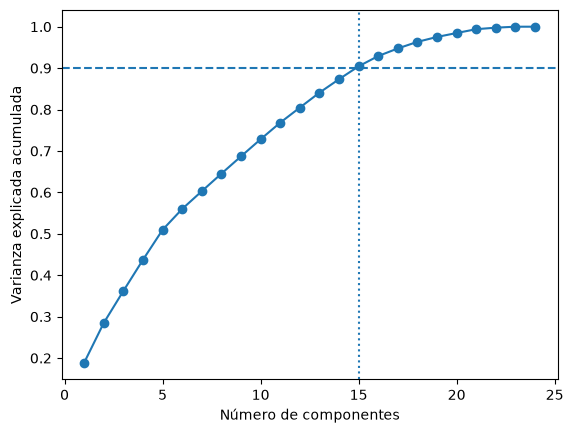

In [9]:
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o')
plt.axhline(0.90, linestyle='--')
plt.axvline(n_componentes, linestyle=':')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.show()


Partí de 24 variables numéricas. Con 14 componentes llego a 87,3 % y con 15 a 90,4 %, así que me quedo con 15. Las 4 categóricas no entran ahí.

Esas componentes sirven para juntar columnas que se mueven juntas. En la primera pesan valor pagado, valor de productos, peso total, precio máximo, volumen y peso máximo: es el tamaño del pedido. No significa que el clasificador vaya a acertar más. Se deja por fuera cerca del 9,6 % de la varianza numérica, y ese 90 % no es la exactitud del modelo.


## 4. Comparación de modelos

Las cuatro configuraciones usan la misma validación, `class_weight='balanced'` y el umbral 0,50. A no usa PCA. B, C y D usan las 15 componentes y solo cambia C.


In [10]:
def preprocesar(usar_pca):
    if usar_pca:
        numericas = make_pipeline(
            SimpleImputer(strategy='median'),
            StandardScaler(),
            PCA(n_components=n_componentes, svd_solver='full', random_state=semilla),
        )
    else:
        numericas = make_pipeline(
            SimpleImputer(strategy='median'),
            StandardScaler(),
        )
    categoricas = make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(handle_unknown='ignore'),
    )
    return ColumnTransformer([
        ('numericas', numericas, columnas_numericas),
        ('categoricas', categoricas, columnas_categoricas),
    ])

filas = []
for nombre, usar_pca, c_valor in [('A', False, 1.0), ('B', True, 1.0),
                                  ('C', True, 0.1), ('D', True, 10.0)]:
    modelo = make_pipeline(
        preprocesar(usar_pca),
        LogisticRegression(C=c_valor, class_weight='balanced',
                           max_iter=1000, random_state=semilla),
    )
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_valid)
    proba = modelo.predict_proba(X_valid)[:, 1]
    filas.append({
        'modelo': nombre,
        'pca': usar_pca,
        'C': c_valor,
        'accuracy': accuracy_score(y_valid, pred),
        'precision': precision_score(y_valid, pred, zero_division=0),
        'recall': recall_score(y_valid, pred),
        'f1': f1_score(y_valid, pred, zero_division=0),
        'ap': average_precision_score(y_valid, proba),
    })

comparacion = pd.DataFrame(filas)
print(comparacion.round(3).to_string(index=False))


modelo   pca    C  accuracy  precision  recall    f1    ap
     A False  1.0     0.661      0.122   0.643 0.205 0.170
     B  True  1.0     0.651      0.113   0.604 0.190 0.139
     C  True  0.1     0.649      0.113   0.612 0.191 0.140
     D  True 10.0     0.649      0.113   0.607 0.190 0.138


A, sin PCA y con C = 1, es el mismo modelo de la semana 12: Accuracy 0,661, Precision 0,122, Recall 0,643, F1 0,205 y AP 0,170.

B mete PCA y deja C = 1. Baja a Accuracy 0,651, Recall 0,604, F1 0,190 y AP 0,139. C y D, que solo cambian la penalización, quedan casi iguales a B: Recall 0,612 y 0,607.

PCA no mejoró la detección de tardíos. Al comprimir las numéricas se fue señal que servía para marcar retrasos. Con las componentes ya puestas, subir o bajar C casi no cambia el resultado.
